# Walk-forward analysis

This notebook reads the files in `results/` and the constants in `config.py`. It does not touch prices. Every number in the text below is printed by a code cell above it.

The question is whether Engle-Granger cointegration measured in a two-year formation window predicts profitable mean reversion in the next six months, for 30 pairs of similar US large-cap stocks, after illustrative costs. The primary measure was fixed in `PREREGISTRATION.md`: the net annualized Sharpe ratio of the COINT variant. Returns are excess returns, so the Sharpe ratio has no risk-free subtraction.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

sys.path.insert(0, os.getcwd())
import config
import pairs

os.makedirs("Images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.options.display.float_format = "{:.4f}".format
pd.options.display.width = 200
pd.options.display.max_columns = 30
COLORS = {"ALL": "#1f6f8b", "COINT": "#c8553d", "COINT_BH": "#2a9d4a"}

summary = pd.read_csv("results/summary.csv")
pw = pd.read_csv("results/pair_windows.csv", parse_dates=["formation_start", "formation_end", "trading_start", "trading_end"])
trades = pd.read_csv("results/trades.csv", parse_dates=["entry_date", "exit_date"])
port = pd.read_csv("results/portfolio_returns.csv", parse_dates=["date"])
cost_sens = pd.read_csv("results/cost_sensitivity.csv")
entry_sens = pd.read_csv("results/entry_sensitivity.csv")
print(f"{len(pw)} pair-windows, {pw.pair.nunique()} pairs, {pw.window.nunique()} windows, {len(trades)} completed trades, {len(port)} portfolio days")
print(f"Trading days covered: {port.date.min().date()} to {port.date.max().date()}")

570 pair-windows, 30 pairs, 19 windows, 440 completed trades, 2394 portfolio days
Trading days covered: 2017-01-03 to 2026-07-14


## 1. Headline table

In [2]:
display(summary.set_index(["variant", "basis"]))
primary = summary[(summary.variant == "COINT") & (summary.basis == "net")].iloc[0]
word = "made" if primary.ann_return > 0 else "lost"
print(f"Primary variant (COINT, net) {word} money: annualized return {primary.ann_return:.4%}, "
      f"annualized volatility {primary.ann_volatility:.4%}, Sharpe {primary.sharpe:.3f}, max drawdown {primary.max_drawdown:.4%}.")

ann_return  ann_volatility  sharpe  max_drawdown  pair_windows_traded  completed_trades  pct_days_open_position  beta_to_spy  corr_to_spy
variant  basis                                                                                                                                           
ALL      gross      0.0084          0.0150  0.5651       -0.0290                  547               440                 99.0393       0.0113       0.1382
         net        0.0057          0.0150  0.3892       -0.0355                  547               440                 99.0393       0.0114       0.1386
COINT    gross      0.0118          0.0294  0.4154       -0.0639                   57                63                 66.2490      -0.0041      -0.0256
         net        0.0091          0.0294  0.3218       -0.0663                   57                63                 66.2490      -0.0042      -0.0259
COINT_BH gross      0.0037          0.0192  0.2013       -0.0396                   12                12                 16.2490      -0.0011      -0.0100
         net        0.0029          0.0192  0.1614       -0.0422                   12                12                 16.2490      -0.0010      -0.0097

Primary variant (COINT, net) made money: annualized return 0.9062%, annualized volatility 2.9374%, Sharpe 0.322, max drawdown -6.6323%.


The primary variant, COINT, made a small profit after costs. Its net annualized return is under one percent, and its net Sharpe ratio is 0.322. The ALL variant, which trades every pair with a positive hedge ratio, has a higher net Sharpe ratio than COINT. So in this sample, filtering on cointegration did not raise the Sharpe ratio. COINT does have the highest net annualized return of the three, but it also has the highest volatility and the deepest drawdown. COINT_BH trades in only 12 pair-windows, so its numbers rest on very little.

## 2. Equity curves (net)

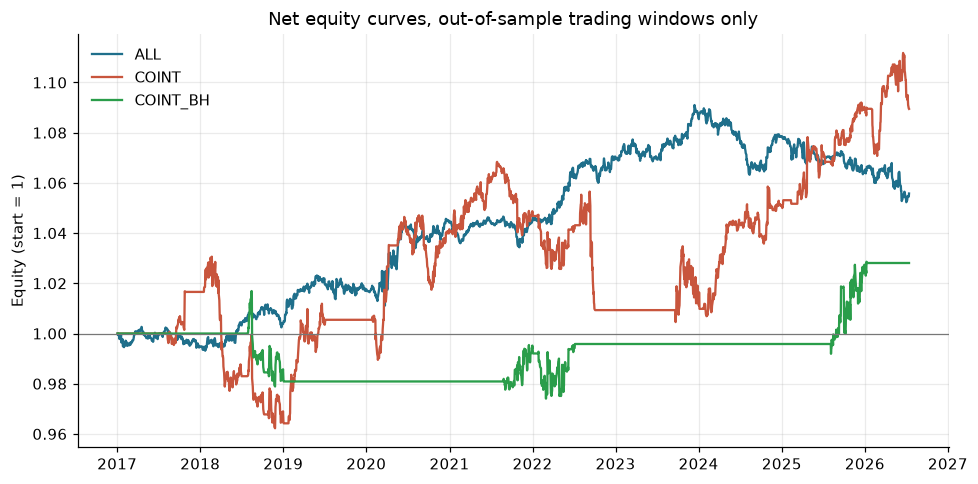

ALL: final equity 1.0558
COINT: final equity 1.0895
COINT_BH: final equity 1.0281


In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for v in ["ALL", "COINT", "COINT_BH"]:
    ax.plot(port.date, np.cumprod(1.0 + port[v]), color=COLORS[v], label=v)
ax.axhline(1.0, color="#777777", lw=0.8)
ax.set_ylabel("Equity (start = 1)")
ax.set_title("Net equity curves, out-of-sample trading windows only")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("Images/equity_curves.png", bbox_inches="tight")
plt.show()
for v in ["ALL", "COINT", "COINT_BH"]:
    print(f"{v}: final equity {np.prod(1.0 + port[v]):.4f}")


The three curves end close to 1, with small gains. The COINT curve has the largest swings, which matches its higher volatility in the table above. I do not read the shape of these curves as evidence for or against the idea. The next sections look at the question more directly.

## 3. How many pairs pass the cointegration test

,pairs_tested,raw_p_below_0.05,bh_rejections,expected_by_chance
window,,,,
0,30,1,0,1.5000
1,30,2,0,1.5000
2,30,2,0,1.5000
3,30,3,2,1.5000
4,30,3,0,1.5000
5,30,0,0,1.5000
6,30,3,0,1.5000
7,30,3,0,1.5000
8,30,5,0,1.5000


Total raw passes: 60, total expected by chance: 28.5, total BH rejections: 12


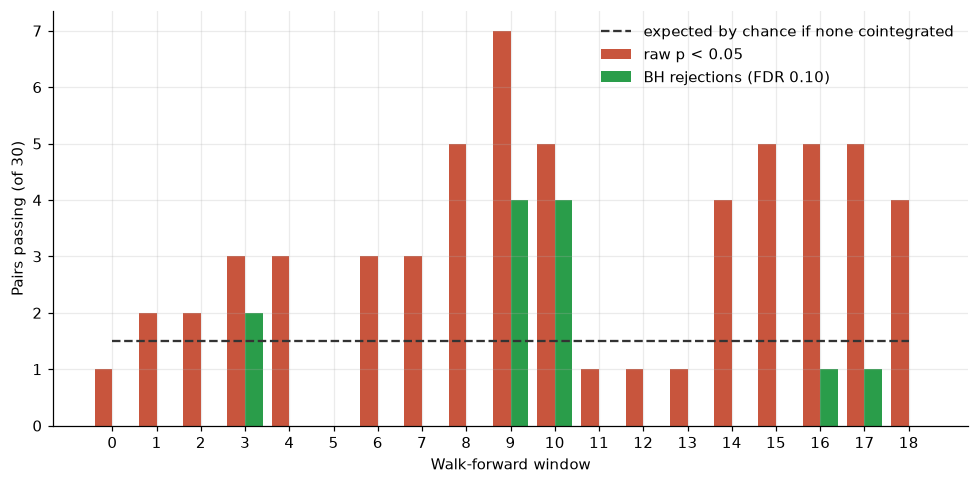

In [4]:
g = pw.groupby("window")
passing = pd.DataFrame({
    "pairs_tested": g.size(),
    "raw_p_below_0.05": g.apply(lambda d: int((d.eg_pvalue < config.COINT_ALPHA).sum()), include_groups=False),
    "bh_rejections": g.bh_reject.sum().astype(int),
})
passing["expected_by_chance"] = passing.pairs_tested * config.COINT_ALPHA
display(passing)
print(f"Total raw passes: {passing['raw_p_below_0.05'].sum()}, total expected by chance: {passing.expected_by_chance.sum():.1f}, total BH rejections: {passing.bh_rejections.sum()}")
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(passing))
ax.bar(x - 0.2, passing["raw_p_below_0.05"], width=0.4, color=COLORS["COINT"], label="raw p < 0.05")
ax.bar(x + 0.2, passing.bh_rejections, width=0.4, color=COLORS["COINT_BH"], label="BH rejections (FDR 0.10)")
ax.plot(x, passing.expected_by_chance, color="#333333", lw=1.5, ls="--", label="expected by chance if none cointegrated")
ax.set_xticks(x)
ax.set_xlabel("Walk-forward window")
ax.set_ylabel("Pairs passing (of 30)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("Images/pairs_passing_per_window.png", bbox_inches="tight")
plt.show()

Across the 19 windows, 60 pair tests have a raw p-value below 0.05. If no pair were cointegrated, I would expect about 28.5 by chance. So the raw passes are about twice the chance level, which is some evidence that a share of these pairs does have a stable long-run relationship. The count is uneven across windows. Windows 9 and 10 have the most, and window 5 has none. Benjamini-Hochberg at a false discovery rate of 0.10 keeps only 12 of the 60 and rejects nothing in most windows. That tells me many of the raw passes are the kind that multiple testing would be expected to produce. The raw counts alone do not separate real relationships from chance.

## 4. Does formation cointegration predict out-of-sample profit?

In [5]:
traded = pw[pw.eligible_ALL].copy()
bins = [-np.inf, 0.01, 0.05, 0.10, np.inf]
labels = ["p < 0.01", "0.01 to 0.05", "0.05 to 0.10", "above 0.10"]
traded["bucket"] = pd.cut(traded.eg_pvalue, bins=bins, labels=labels, right=False)
traded.loc[traded.eg_pvalue == 0.10, "bucket"] = "0.05 to 0.10"
table = traded.groupby("bucket", observed=True).net_return.agg(["count", "mean", "median"])
display(table.reindex(labels))
rho, rho_p = stats.spearmanr(traded.eg_pvalue, traded.net_return)
print(f"Spearman rank correlation between eg_pvalue and net_return: {rho:.4f} (p-value {rho_p:.4f}), n = {len(traded)}")

,count,mean,median
bucket,,,
p < 0.01,16,0.0040,0.0022
0.01 to 0.05,41,0.0085,0.0000
0.05 to 0.10,36,0.0068,0.0000
above 0.10,454,0.0023,0.0000


Spearman rank correlation between eg_pvalue and net_return: -0.0161 (p-value 0.7074), n = 547


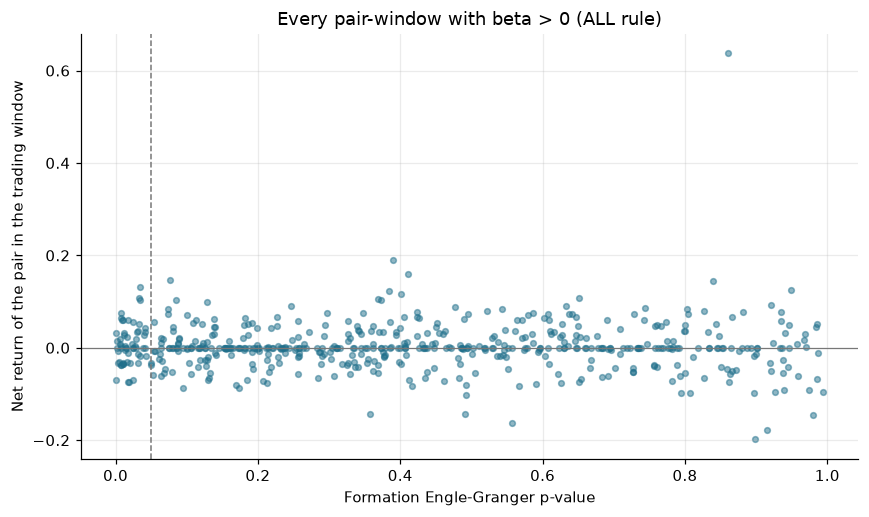

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(traded.eg_pvalue, traded.net_return, s=14, alpha=0.5, color=COLORS["ALL"])
ax.axvline(config.COINT_ALPHA, color="#777777", ls="--", lw=1)
ax.axhline(0.0, color="#777777", lw=0.8)
ax.set_xlabel("Formation Engle-Granger p-value")
ax.set_ylabel("Net return of the pair in the trading window")
ax.set_title("Every pair-window with beta > 0 (ALL rule)")
fig.tight_layout()
fig.savefig("Images/pvalue_vs_return.png", bbox_inches="tight")
plt.show()

The mean net return is positive in every p-value bucket, but the medians are zero in three of the four buckets. Of the 547 eligible pair-windows, 146 never trade, because the z-score never reaches the entry line, so they return exactly zero. The Spearman rank correlation between the formation p-value and the net return is close to zero and its p-value is large. I find no sign that a lower formation p-value goes with a better out-of-sample return. The bucket with p between 0.01 and 0.05 has the highest mean, the bucket with p below 0.01 has a lower one, and the counts in the low buckets are small. I would not read an ordering into the bucket means.

## 5. Does the relationship persist out of sample?

In [7]:
elig = pw[pw.eligible_COINT]
share = (elig.oos_adf_pvalue < 0.05).mean()
print(f"COINT-eligible pair-windows: {len(elig)}")
print(f"Share whose trading-window spread has ADF p < 0.05: {share:.4f} ({int((elig.oos_adf_pvalue < 0.05).sum())} of {len(elig)})")
rest = pw[pw.eligible_ALL & ~pw.eligible_COINT]
print(f"For comparison, other beta > 0 pair-windows: {(rest.oos_adf_pvalue < 0.05).mean():.4f} ({int((rest.oos_adf_pvalue < 0.05).sum())} of {len(rest)})")

COINT-eligible pair-windows: 57
Share whose trading-window spread has ADF p < 0.05: 0.1053 (6 of 57)
For comparison, other beta > 0 pair-windows: 0.0918 (45 of 490)


Among COINT-eligible pair-windows, only 6 of 57 have a trading-window spread that rejects a unit root at the 5 percent level. For the other pair-windows with a positive beta the share is about the same. A 126-day ADF test has low power, so this is indicative only. Still, it gives no sign that the relationship found in formation carried over into the trading window more often for the eligible pairs.

## 6. How trades end

In [8]:
def exit_table(df):
    out = df.groupby("exit_reason").net_return.agg(["count", "mean"])
    out["share"] = out["count"] / out["count"].sum()
    return out[["count", "share", "mean"]].rename(columns={"mean": "mean_net_trade_return"})
print("All completed trades (ALL rule):")
display(exit_table(trades))
print("Trades in COINT-eligible pair-windows:")
display(exit_table(trades[trades.eligible_COINT]))

All completed trades (ALL rule):


,count,share,mean_net_trade_return
exit_reason,,,
revert,108,0.2455,0.0624
stop,105,0.2386,-0.0574
window_end,227,0.5159,0.0041


Trades in COINT-eligible pair-windows:


,count,share,mean_net_trade_return
exit_reason,,,
revert,25,0.3968,0.0395
stop,19,0.3016,-0.0392
window_end,19,0.3016,0.0084


This is where the losses show up. Trades that revert make money and trades that hit the stop lose about as much as the reverting trades gain on average, but the stops are nearly as common as the reverts. Among COINT-eligible pair-windows, stops are 30 percent of trades, and the average stopped trade loses about as much as the average reverting trade gains. Trades that are still open at the window end are the most common exit under the ALL rule, and their mean return is near zero. The strategy's result is a net of large gains and large losses.

## 7. Market neutrality

In [9]:
display(summary[summary.basis == "net"][["variant", "beta_to_spy", "corr_to_spy"]].set_index("variant"))

,beta_to_spy,corr_to_spy
variant,,
ALL,0.0114,0.1386
COINT,-0.0042,-0.0259
COINT_BH,-0.0010,-0.0097


All three variants have a beta to SPY close to zero and a low correlation with SPY. The long-short construction removes most of the market exposure, so the returns are mostly unrelated to what the stock market did.

## 8. Uncertainty

In [10]:
pair_means = elig.groupby("pair").net_return.mean()
all_pairs = pw.pair.nunique()
excluded = all_pairs - len(pair_means)
print(f"Pairs with at least one COINT-eligible pair-window: {len(pair_means)}; pairs never eligible (excluded): {excluded}")
boot_means = pairs.pair_bootstrap_means(pair_means.to_numpy())
pm_lo, pm_hi = np.percentile(boot_means, [2.5, 97.5])
print(f"Mean of per-pair mean net returns: {pair_means.mean():.6f}")
print(f"Pair-level bootstrap, indicative 95% interval: [{pm_lo:.6f}, {pm_hi:.6f}] ({config.BOOTSTRAP_REPS} reps, seed {config.RANDOM_SEED})")

Pairs with at least one COINT-eligible pair-window: 22; pairs never eligible (excluded): 8
Mean of per-pair mean net returns: -0.001115
Pair-level bootstrap, indicative 95% interval: [-0.016123, 0.013830] (10000 reps, seed 42)


In [11]:
coint_net = port["COINT"].to_numpy()
sharpe_point = pairs.sharpe(coint_net)
boot_sharpe = pairs.block_bootstrap_sharpe(coint_net)
sh_lo, sh_hi = np.percentile(boot_sharpe, [2.5, 97.5])
print(f"COINT net Sharpe: {sharpe_point:.4f}")
print(f"Circular block bootstrap, indicative 95% interval: [{sh_lo:.4f}, {sh_hi:.4f}] "
      f"(block length {config.BLOCK_LENGTH}, {config.BOOTSTRAP_REPS} reps, seed {config.RANDOM_SEED})")
boot = pd.DataFrame([
    {"quantity": "mean_per_pair_net_pair_window_return_COINT", "estimate": pair_means.mean(), "ci_low": pm_lo, "ci_high": pm_hi,
     "n_units": len(pair_means), "reps": config.BOOTSTRAP_REPS},
    {"quantity": "net_sharpe_COINT", "estimate": sharpe_point, "ci_low": sh_lo, "ci_high": sh_hi,
     "n_units": len(coint_net), "reps": config.BOOTSTRAP_REPS},
])
boot.to_csv("results/bootstrap.csv", index=False)

COINT net Sharpe: 0.3218
Circular block bootstrap, indicative 95% interval: [-0.3572, 0.9916] (block length 21, 10000 reps, seed 42)


I resample pairs, not pair-windows. Pair-windows from the same pair share the same two stocks, and all pairs share the same market history, so they are not independent draws. Treating the 57 eligible pair-windows as independent would make the interval look narrower than it should. The unit of one pair is the coarser choice. This is an indicative resampling interval for this universe of 30 pairs, not a formal confidence statement about all equities.

The pair-level interval for the mean net return per pair spans zero. The mean of the per-pair means is slightly negative, while the portfolio return is slightly positive. These differ because the portfolio weights each pair-window equally within a window, while the pair-level figure averages by pair, so pairs with few eligible windows count as much as pairs with many. The block bootstrap interval for the COINT net Sharpe ratio also spans zero. The data are compatible with no net edge after costs.

## 9. Where V/MA sits

V/MA mean net pair-window return (ALL rule): 0.011406
Percentile among 30 pairs: 83.3


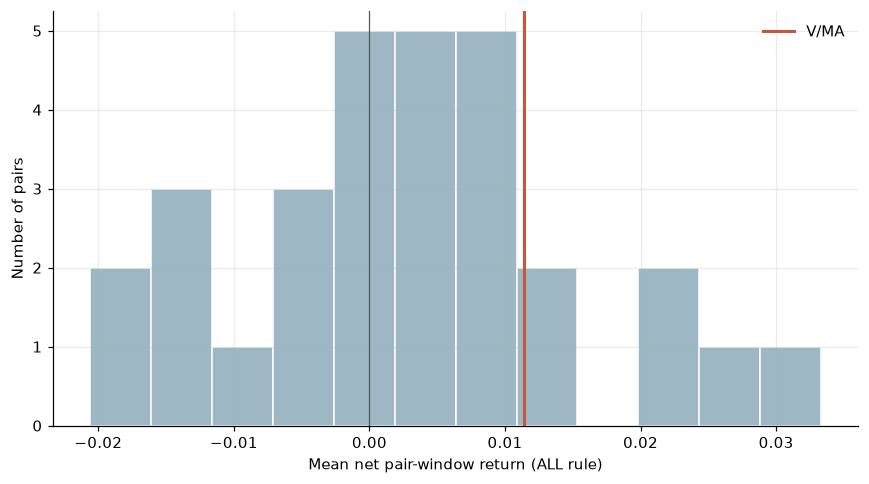

Best pair: AXP/COF (0.033339); worst pair: SHW/PPG (-0.020635)


In [12]:
per_pair = traded.groupby("pair").net_return.mean()
vma = per_pair["V/MA"]
pct = stats.percentileofscore(per_pair.to_numpy(), vma, kind="rank")
print(f"V/MA mean net pair-window return (ALL rule): {vma:.6f}")
print(f"Percentile among {len(per_pair)} pairs: {pct:.1f}")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(per_pair, bins=12, color="#9db8c4", edgecolor="white")
ax.axvline(vma, color=COLORS["COINT"], lw=2, label="V/MA")
ax.axvline(0.0, color="#555555", lw=0.8)
ax.set_xlabel("Mean net pair-window return (ALL rule)")
ax.set_ylabel("Number of pairs")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("Images/vma_in_distribution.png", bbox_inches="tight")
plt.show()
print(f"Best pair: {per_pair.idxmax()} ({per_pair.max():.6f}); worst pair: {per_pair.idxmin()} ({per_pair.min():.6f})")

V/MA sits in the upper part of the 30 pairs on mean net pair-window return under the ALL rule, at the percentile printed above. It is not the best pair. With 30 pairs, some pair has to be near the top, so I treat this as an observation about where the case study from the first notebook falls, not as a reason to single the pair out.

## 10. Robustness checks

These tables are robustness checks of the pre-registered setting. They are not a search for a better one. The primary result always uses an entry threshold of 2.0 and a cost of 5 bps.

In [13]:
print("Cost sensitivity (entry 2.0):")
display(cost_sens.pivot(index="cost_bps", columns="variant", values=["net_sharpe", "net_ann_return"]))
print("Entry threshold sensitivity (cost 5 bps):")
display(entry_sens.pivot(index="entry_z", columns="variant", values=["net_sharpe", "net_ann_return"]))

Cost sensitivity (entry 2.0):


net_sharpe                 net_ann_return                
variant         ALL  COINT COINT_BH            ALL  COINT COINT_BH
cost_bps                                                          
0.0000       0.4963 0.3865   0.1889         0.0073 0.0110   0.0034
2.0000       0.4535 0.3607   0.1779         0.0067 0.0102   0.0032
5.0000       0.3892 0.3218   0.1614         0.0057 0.0091   0.0029
10.0000      0.2817 0.2569   0.1339         0.0041 0.0071   0.0024

Entry threshold sensitivity (cost 5 bps):


net_sharpe                 net_ann_return                
variant        ALL  COINT COINT_BH            ALL  COINT COINT_BH
entry_z                                                          
1.5000      0.1470 0.1059   0.0809         0.0025 0.0032   0.0015
2.0000      0.3892 0.3218   0.1614         0.0057 0.0091   0.0029
2.5000      0.4024 0.1454   0.2047         0.0049 0.0029   0.0033

Higher costs lower the Sharpe ratio of every variant, as expected. The entry-threshold table does not move in one direction. COINT is much weaker at both 1.5 and 2.5 than at 2.0, and ALL is about the same at 2.0 and 2.5. This pattern is mostly a sign of how noisy these estimates are. I did not use these tables to choose a setting, and the primary result stays at an entry of 2.0 and 5 bps.

## 11. What this shows and what it does not

**What this shows.** For these 30 pairs over the trading periods printed at the top (2017 to 2026), the pre-registered COINT strategy earned a small positive net return of under one percent a year, with a net Sharpe ratio of 0.322. The indicative interval for that Sharpe ratio includes zero. The ALL variant, which ignores cointegration, has a higher net Sharpe ratio. Formation p-values do not rank pair-windows by out-of-sample return: the Spearman correlation is near zero. The raw p-value passes are about twice what chance alone would give, but most disappear under Benjamini-Hochberg, and the out-of-sample ADF share for eligible pairs is low. The strategy is nearly market neutral. Its trades end at the stop about as often as they revert, which is where the losses are.

**What it does not show.** It does not show that cointegration has no predictive value in general. It is 30 pairs chosen with hindsight about which firms look similar, from today's surviving large caps, over one market history. The direction of the resulting bias is not known. Engle-Granger has limited power in a two-year window and depends on which ticker is Y. Costs of 5 bps and a 0.50 percent borrow fee are illustrative assumptions, and bid-ask spread, slippage, and daily rebalancing costs are not modeled. Any explanation for why one pair or window did better than another would be post hoc. The right reading is that in this sample, the cointegration filter did not improve the result I measured.

## Sensitivity checks added after the first version

These three tables were added after the first version. The plan for the rebalancing cost is in `UPGRADE_PLAN.md`, and the README explains all three.

In [14]:
print("Execution lag sensitivity:")
display(pd.read_csv("results/execution_lag_sensitivity.csv").round(4))

Execution lag sensitivity:


,variant,lag_days,net_sharpe,net_ann_return,net_max_drawdown,sharpe_ci_low,sharpe_ci_high
0,ALL,1,0.3892,0.0057,-0.0355,-0.1361,0.8969
1,COINT,1,0.3218,0.0091,-0.0663,-0.3572,0.9916
2,COINT_BH,1,0.1614,0.0029,-0.0422,-0.2743,0.5695
3,ALL,2,0.4086,0.0060,-0.0361,-0.1121,0.9282
4,COINT,2,0.0957,0.0024,-0.0677,-0.5401,0.7079
5,COINT_BH,2,0.1358,0.0024,-0.0541,-0.3268,0.5544


In [15]:
print("ALL variant sensitivity:")
display(pd.read_csv("results/all_variant_sensitivity.csv").round(4))

ALL variant sensitivity:


,case,variant,eligible_pair_windows,net_sharpe,net_ann_return
0,as published,COINT,57,0.3218,0.0091
1,as published,ALL,547,0.3892,0.0057
2,ALL with beta at least 0.1,ALL,541,0.4281,0.0060
3,ALL with beta at least 0.3,ALL,509,0.4321,0.0055
4,ALL with beta at least 0.5,ALL,455,0.5693,0.0074
5,"ALL without its best pair-window (AXP/COF, win...",ALL,546,0.2753,0.0038


In [16]:
print("Rebalancing cost sensitivity:")
display(pd.read_csv("results/rebalance_cost_sensitivity.csv").round(4))

Rebalancing cost sensitivity:


,variant,net_sharpe,net_sharpe_with_rebalance_cost,net_ann_return,net_ann_return_with_rebalance_cost,max_drawdown,max_drawdown_with_rebalance_cost,mean_daily_rebalance_cost_bps
0,ALL,0.3892,0.3745,0.0057,0.0055,-0.0355,-0.0361,0.0087
1,COINT,0.3218,0.3183,0.0091,0.0090,-0.0663,-0.0664,0.0041
2,COINT_BH,0.1614,0.1600,0.0029,0.0029,-0.0422,-0.0423,0.0010
